# Étude de cas 3 – Jalon 1 : des descripteurs à la décision

***Par:***
- **AARROUB Wijdane**
- **AIT EL MAHJOUB Abdessamad**
- **TOKO Rayane**

---

**CardioPatch – télésurveillance cardiaque** · M2 SDIA – Advanced Artificial Intelligence – 2026–2027

**Protocole** : tous les réglages (perte, groupes de descripteurs, seuil) sont faits sur la **validation** (et, pour le seuil, sur un pool train + validation découpé par patient) ; l'ensemble de **test n'est utilisé qu'une seule fois**, à la fin, pour le modèle retenu.

**Version fusionnée : ce qui vient d'où**
- *Du premier notebook* : protocole à **5 graines** pour toutes les comparaisons, lectures écrites, page de décisions, journal.
- *De versions d'autres membres du groupe* : détecteur QRS à seuil adaptatif (médiane + k×MAD, `k` réglé sur le **train** uniquement), descripteurs de pause AV (`ratio_pause`), descripteurs spectraux, idée du **seuil calibré hors pli** (out-of-fold) sur train + validation. À signaler dans le rendu selon les règles de collaboration du cours.
- *Corrections de cette fusion* : modèle final **entraîné comme les modèles du seuil hors pli** (même perte, même pondération, mêmes époques), choix de la perte par une règle explicite (plus de départage par égalité), et définition correcte de « sinus non signalés ».

**Avertissement**
- Les données couvrent  **280 / 60 / 60 patients** en train / validation / test (soit 8400 / 1800 / 1800 fenêtres, **30 fenêtres par patient**). La validation reste modeste (60 patients, 238 fenêtres de FA)
- Les classes sont déséquilibrées : en train `[4348, 1209, 1018, 995, 830]`, en validation `[892, 238, 292, 198, 180]`, en test `[870, 280, 205, 152, 293]`.

**Modifications après relecture (cette version)**
- `seuil_specificite` est la fonction **du sujet, inchangée** (plus de `method="higher"`).
- **Arrêt précoce** (`EarlyStopping` sur `val_loss`) intégré dans le procédé d'entraînement commun, activable par `USE_ES` ; les comparaisons restent à **5 graines**. La section 6bis compare avec et sans arrêt précoce. Tous les chiffres et toutes les lectures ci-dessous sont ceux de cette nouvelle exécution.

## Plan (correspondance avec le sujet)

| Partie | Ce que demande le sujet |
|---|---|
| 0. Chargement | Données, découpage par patient |
| 1. Vérification théorique | Poids de classes (à la main, puis code) ; perte et gradient de l'entropie croisée |
| 2. Descripteurs | Détection des QRS + 11 descripteurs de base + 3 groupes d'enrichissement |
| 3. Utilitaires | MLP, pertes, métriques, journal d'expériences |
| **Question 1** | MLP de référence : matrice de confusion, rappels, échecs de détection QRS (signaux affichés) |
| **Question 2** | Entropie croisée simple / pondérée / perte focale, effet sur les classes rares |
| **Question 3** | Enrichissement des descripteurs et ablation par groupe |
| **Question 4** | Seuil d'alerte « fibrillation atriale » à 95 % de spécificité, sensibilité obtenue |
| 4. Test | Évaluation finale, une seule fois, écart aux cibles |
| 5. Journal | Journal d'expériences (`jalon=1`) |
| 6. Page de décisions | Tableau des résultats, choix justifiés (coût clinique), réponses théoriques |

In [ ]:
import os, sys, random, platform, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")
import sklearn, scipy
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import beta
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, recall_score, roc_curve, roc_auc_score
from IPython.display import display, Markdown

SEED_FINAL = 42            # graine du modèle final, du seuil et du test
SEEDS = list(range(5))     # 5 graines pour toutes les comparaisons
def fixer_graine(s=SEED_FINAL):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
fixer_graine()

# Recherche automatique du fichier .npz Holter (ex: uc3_holterA.npz) dans les emplacements courants
CANDIDATS = [
    os.environ.get("uc3_holterA", ""),
    "./",
    "data/",
    "/content/",
    "/content/data/",
    "/content/drive/MyDrive/tp-ia-avancee-npy/",
    "/content/drive/MyDrive/data-npz/",
    "/mnt/user-data/uploads/"
]

CHEMIN_HOLTER = None
for d in CANDIDATS:
    if not d: continue
    # Vérifie les noms possibles du fichier .npz Holter
    for nom_fich in ["uc3_holterA.npz", "holterA.npz", "uc3_holter.npz"]:
        p = os.path.join(d, nom_fich)
        if os.path.exists(p):
            CHEMIN_HOLTER = p
            break
    if CHEMIN_HOLTER:
        break

# Si non trouvé par nom exact, cherche n'importe quel .npz contenant "holter"
if not CHEMIN_HOLTER:
    for d in CANDIDATS:
        if not d or not os.path.exists(d): continue
        for f in os.listdir(d):
            if f.endswith(".npz") and "holter" in f.lower():
                CHEMIN_HOLTER = os.path.join(d, f)
                break
        if CHEMIN_HOLTER: break

print("Fichier NPZ Holter sélectionné :", CHEMIN_HOLTER)
FS = 125
NOMS = ["sinusal", "FA", "ESV", "tachy.", "BAV2"]
print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sklearn", sklearn.__version__, "| TF", tf.__version__, "| Keras", keras.__version__)

Fichier NPZ Holter sélectionné : ./uc3_holterA.npz
Python 3.13.15 | numpy 2.1.3 | scipy 1.16.3 | sklearn 1.6.1 | TF 2.21.0 | Keras 3.13.2


## 0. Chargement des données (découpage imposé par patient)

In [2]:
def sexe_en_nombre(v):
    v = np.asarray(v)
    if v.dtype.kind in "US":
        return np.array([{"M": 1.0, "H": 1.0, "F": 0.0}.get(str(x).upper(), 0.0) for x in v], dtype="float32")
    return v.astype("float32")

def charger_npz(chemin, s):
    """Charge un split depuis le fichier .npz officiel."""
    npz = np.load(chemin, allow_pickle=True)
    cles = npz.files
    def cle(*options):
        for o in options:
            if o in cles:
                return o
        raise KeyError(f"Aucune des clés {options} trouvée parmi {cles}")
    return dict(
        X=npz[cle(f"X_{s}")].astype("float32"),
        y=npz[cle(f"y_{s}", f"classe_{s}")].astype(int),
        fc=npz[cle(f"fc_{s}")].astype("float32"),
        pat=npz[cle(f"patient_{s}", f"pat_{s}")],
        age=npz[cle(f"age_{s}")].astype("float32"),
        sex=sexe_en_nombre(npz[cle(f"sexe_{s}", f"sex_{s}")]),
    )

assert CHEMIN_HOLTER is not None, "❌ Erreur : Le fichier .npz Holter est introuvable. Vérifiez son emplacement."

# Chargement du dictionnaire A à partir du fichier .npz
A = {s: charger_npz(CHEMIN_HOLTER, s) for s in ["train", "val", "test"]}

for s in A:
    print(s, A[s]["X"].shape, "patients:", len(set(A[s]["pat"])), "| effectifs par classe:", np.bincount(A[s]["y"], minlength=5))

P = {s: set(A[s]["pat"]) for s in A}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"])
print("Découpage par patient vérifié : aucun patient partagé.")
Y = {s: A[s]["y"] for s in A}

train (8400, 1250) patients: 280 | effectifs par classe: [4348 1209 1018  995  830]
val (1800, 1250) patients: 60 | effectifs par classe: [892 238 292 198 180]
test (1800, 1250) patients: 60 | effectifs par classe: [870 280 205 152 293]
Découpage par patient vérifié : aucun patient partagé.


**Format.** `X` : (fenêtres × 1250), 10 s à 125 Hz en mV ; `classe` : 0 sinusal, 1 FA, 2 ESV, 3 tachycardie, 4 BAV2 ; `fc` : fréquence cardiaque annotée ; `patient`, `age`, `sexe`.

**Point d'attention** : la validation ne contient que 60 patients et 238 fenêtres de FA, et la répartition des classes diffère entre ensembles (graphique ci-dessous). Toute conclusion tirée de la seule validation reste fragile, même si l'effectif est désormais suffisant pour des estimations crédibles.

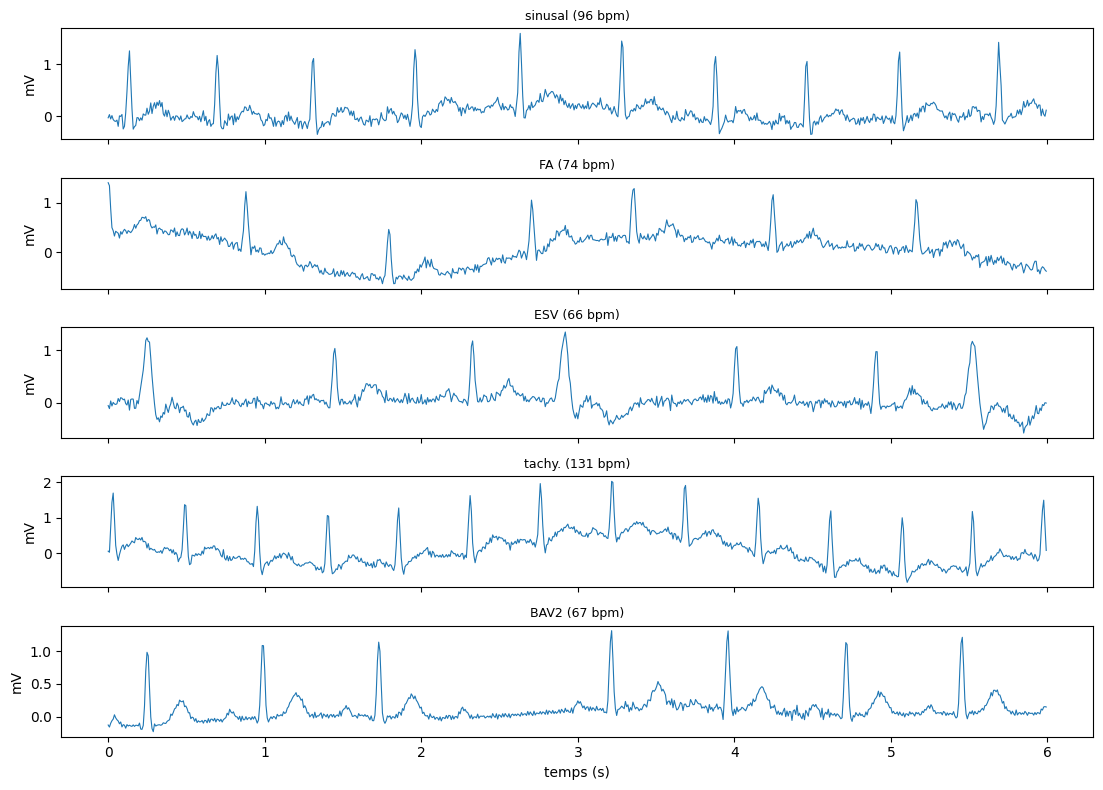

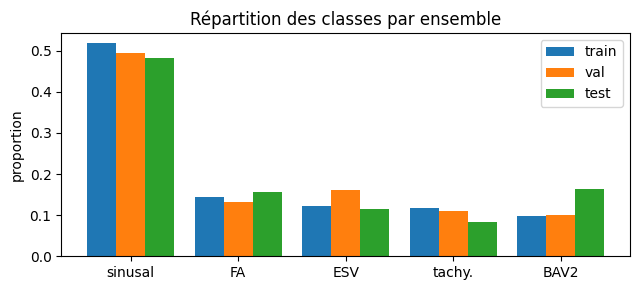

In [3]:
fig, axs = plt.subplots(5, 1, figsize=(11, 8), sharex=True)
t6 = np.arange(6*FS)/FS
for k, ax in enumerate(axs):
    i = np.where(A["train"]["y"] == k)[0][0]
    ax.plot(t6, A["train"]["X"][i][:6*FS], lw=.8, color="tab:blue")
    ax.set_title("%s (%.0f bpm)" % (NOMS[k], A["train"]["fc"][i]), fontsize=9); ax.set_ylabel("mV")
axs[-1].set_xlabel("temps (s)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3))
for j, (s_, c_) in enumerate(zip(["train", "val", "test"], ["tab:blue", "tab:orange", "tab:green"])):
    ax.bar(np.arange(5)+0.27*j, np.bincount(A[s_]["y"], minlength=5)/len(A[s_]["y"]), width=0.27, label=s_, color=c_)
ax.set_xticks(np.arange(5)+0.27); ax.set_xticklabels(NOMS); ax.set_ylabel("proportion")
ax.set_title("Répartition des classes par ensemble"); ax.legend(); plt.tight_layout(); plt.show()

## 1. Vérification théorique (à la main, puis vérifiée par le code)

### 1.1 Poids de classes $w_k = \dfrac{N}{K\,N_k}$

Effectifs d'entraînement : $N_k = (4348,\ 1209,\ 1018,\ 995,\ 830)$, $N = 8400$, $K = 5$.

| classe | $N_k$ | calcul | $w_k$ |
|---|---|---|---|
| sinusal | 4348 | $8400/(5\times4348) = 8400/21740$ | **0,386** |
| FA | 1209 | $8400/(5\times1209) = 8400/6045$ | **1,390** |
| ESV | 1018 | $8400/(5\times1018) = 8400/5090$ | **1,650** |
| tachycardie | 995 | $8400/(5\times995) = 8400/4975$ | **1,688** |
| BAV2 | 830 | $8400/(5\times830) = 8400/4150$ | **2,024** |

Une classe rare reçoit un poids > 1, la classe majoritaire un poids < 1 ; la BAV2 (la plus rare en train) a le poids le plus fort. Par construction $\sum_k N_k w_k = N$ : la perte totale garde le même ordre de grandeur.

### 1.2 Entropie croisée et gradient

Probabilités $p = (0{,}50;\ 0{,}30;\ 0{,}10;\ 0{,}05;\ 0{,}05)$, vraie classe = 1 (FA), $y = (0,1,0,0,0)$.

- Perte : $L = -\ln p_1 = -\ln 0{,}30 \approx \mathbf{1{,}204}$.
- Avec softmax, $p_k = e^{z_k}/\sum_j e^{z_j}$, d'où $\dfrac{\partial L}{\partial z_k} = p_k - y_k$ :
  $\dfrac{\partial L}{\partial z} = (0{,}50;\ -0{,}70;\ 0{,}10;\ 0{,}05;\ 0{,}05)$.
- Lecture : le gradient de la vraie classe est négatif (descente de gradient : son logit **augmente**), les autres sont positifs (leurs logits **diminuent**) ; la somme vaut 0 car $\sum_k p_k = \sum_k y_k = 1$.

In [4]:
Nk = np.bincount(A["train"]["y"], minlength=5); N = Nk.sum(); K = 5
w = N / (K * Nk)
for k in range(5):
    print(f"{NOMS[k]:8s}  w = {N} / ({K} x {Nk[k]:3d}) = {w[k]:.3f}")
print("Somme N_k * w_k =", float((Nk*w).sum()), "(= N)")

p = np.array([0.50, 0.30, 0.10, 0.05, 0.05]); y = np.eye(5)[1]
print("\nPerte  = -ln(0.30) =", round(-np.log(p[1]), 4))
print("p - y             =", (p - y).round(2))
z = tf.Variable(np.log(p)[None, :], dtype=tf.float64)
with tf.GradientTape() as tape:
    perte = tf.keras.losses.categorical_crossentropy(y[None, :], tf.nn.softmax(z))
print("Autodiff : perte =", round(float(perte[0]), 4), "| gradient =", tape.gradient(perte, z).numpy().round(2)[0])

sinusal   w = 8400 / (5 x 4348) = 0.386
FA        w = 8400 / (5 x 1209) = 1.390
ESV       w = 8400 / (5 x 1018) = 1.650
tachy.    w = 8400 / (5 x 995) = 1.688
BAV2      w = 8400 / (5 x 830) = 2.024
Somme N_k * w_k = 8400.0 (= N)

Perte  = -ln(0.30) = 1.204
p - y             = [ 0.5  -0.7   0.1   0.05  0.05]
Autodiff : perte = 1.204 | gradient = [ 0.5  -0.7   0.1   0.05  0.05]


## 2. Détection des QRS et descripteurs

**Détection (adaptative).** Passe-haut 0,5 Hz → passe-bande 3–25 Hz → z-score → énergie lissée (80 ms) → seuil `médiane + k × MAD` → pics (distance ≥ 0,3 s, proéminence) → rejet des ondes T (pic proche et faible) → garde-fou physiologique (RR ≥ 0,3 s). **`k` est choisi sur le train seul** en minimisant l'écart moyen entre fréquence détectée et fréquence annotée `fc`.

**Descripteurs, 4 groupes** :
- **base** (11) : statistiques RR (moyenne, écart-type, min, max, médiane, RMSSD, CV), nombre de QRS, énergie, âge, sexe ;
- **amplitude/largeur** des complexes (moyenne et dispersion) ;
- **bandes** : part d'énergie par bande de fréquences (0,5–5, 5–15, 15–40, > 40 Hz) + descripteurs spectraux (fréquence dominante, centroïde, entropie spectrale, part 5–25 Hz) ;
- **irrégularité** : pNN50, SD1/SD2, entropie d'échantillon, parts d'intervalles courts/longs, résidu de rythme, entropie RR, **`ratio_pause`** (RR max / médiane, signature d'une pause AV).

In [5]:
def filtre_butter(sig, kind, coupure, ordre):
    nyq = FS/2
    freq = [c/nyq for c in coupure] if kind == "band" else coupure/nyq
    b, a = butter(ordre, freq, btype=kind); return filtfilt(b, a, sig)

def detecter_qrs(x, k_mad=3.5):
    sans_derive = filtre_butter(x, "high", 0.5, 2)
    bande = filtre_butter(sans_derive, "band", (3, 25), 4)
    zc = (bande - bande.mean())/(bande.std() + 1e-8)
    larg = int(0.08*FS)
    e = np.convolve(zc**2, np.ones(larg)/larg, mode="same")
    med = np.median(e); mad = np.median(np.abs(e - med)) + 1e-8
    seuil = med + k_mad*mad
    cand, _ = find_peaks(e, distance=int(0.3*FS), height=seuil, prominence=0.3*seuil)
    if len(cand) == 0: return cand, bande
    gardes = [cand[0]]
    for p_ in cand[1:]:
        if (p_ - gardes[-1])/FS < 0.36 and e[p_] < 0.5*e[gardes[-1]]: continue   # onde T probable
        gardes.append(p_)
    pics = [gardes[0]]
    for p_ in gardes[1:]:
        if (p_ - pics[-1])/FS >= 0.3: pics.append(p_)
    return np.array(pics), bande

def fc_depuis_pics(pics):
    return 60.0/(np.diff(pics)/FS).mean() if len(pics) >= 2 else 0.0

def choisir_k_mad(signaux, fc_ref, grille=np.arange(2.5, 6.5, 0.5)):
    err = {float(k): float(np.mean([abs(fc_depuis_pics(detecter_qrs(s, k)[0]) - f_) for s, f_ in zip(signaux, fc_ref)])) for k in grille}
    best = min(err, key=err.get); print("k_mad retenu (réglé sur le train) :", best, "| écart moyen de FC :", round(err[best], 2), "bpm"); return best
K_MAD = choisir_k_mad(A["train"]["X"], A["train"]["fc"])

for s in ["train", "val"]:
    print(f"\nÉcart de fréquence cardiaque détectée vs annotée ({s}) :")
    for k in range(5):
        idx = np.where(Y[s] == k)[0]
        ec = [abs(fc_depuis_pics(detecter_qrs(A[s]["X"][i], K_MAD)[0]) - A[s]["fc"][i]) for i in idx]
        print(f"  {NOMS[k]:8s} {np.mean(ec):5.1f} bpm (n={len(idx)})")

k_mad retenu (réglé sur le train) : 6.0 | écart moyen de FC : 0.29 bpm

Écart de fréquence cardiaque détectée vs annotée (train) :
  sinusal    0.2 bpm (n=4348)
  FA         0.3 bpm (n=1209)
  ESV        0.1 bpm (n=1018)
  tachy.     0.2 bpm (n=995)
  BAV2       0.9 bpm (n=830)

Écart de fréquence cardiaque détectée vs annotée (val) :
  sinusal    0.2 bpm (n=892)
  FA         0.2 bpm (n=238)
  ESV        0.2 bpm (n=292)
  tachy.     0.2 bpm (n=198)
  BAV2       0.8 bpm (n=180)


In [6]:
def sampen(r, m=2, k=0.2):
    if len(r) < m+3: return 0.
    r = np.asarray(r); tol = k*np.std(r) + 1e-9
    def cnt(m):
        t = np.array([r[i:i+m] for i in range(len(r)-m)])
        d = np.max(np.abs(t[:, None]-t[None]), axis=2); return (np.sum(d <= tol)-len(t))/2
    a_, b_ = cnt(m+1), cnt(m)
    return float(-np.log((a_+1e-9)/(b_+1e-9))) if b_ > 0 else 0.

def descripteurs_fenetre(x, age, sexe):
    pics, f = detecter_qrs(x, K_MAD)
    rr = np.diff(pics)/FS if len(pics) > 2 else np.array([1., 1.])
    med = np.median(rr); d = np.diff(rr) if len(rr) > 1 else np.array([0.])
    base = dict(nb=len(pics), mrr=rr.mean(), srr=rr.std(), rmssd=np.sqrt(np.mean(d**2)), cv=rr.std()/rr.mean(),
                minrr=rr.min(), maxrr=rr.max(), medrr=med, energie=float(np.mean(x**2)), age=age, sexe=sexe)
    demi = int(0.08*FS)
    amp = np.array([np.abs(f[max(0, i-demi):i+demi+1]).max() for i in pics]) if len(pics) else np.array([0.])
    larg = [np.sum(np.abs(f[max(0, i-15):i+16]) > 0.5*np.abs(f[max(0, i-15):i+16]).max())/FS for i in pics]
    ampl = dict(ampm=amp.mean(), amps=amp.std()/(amp.mean()+1e-9),
                larg=np.mean(larg) if larg else 0, largs=np.std(larg) if larg else 0)
    Pw = np.abs(np.fft.rfft(x-x.mean()))**2; fr = np.fft.rfftfreq(len(x), 1/FS); tot = Pw.sum()+1e-9
    dens = Pw/tot; pos = dens[dens > 0]
    bandes = dict(b1=Pw[(fr >= .5) & (fr < 5)].sum()/tot, b2=Pw[(fr >= 5) & (fr < 15)].sum()/tot,
                  b3=Pw[(fr >= 15) & (fr < 40)].sum()/tot, b4=Pw[fr >= 40].sum()/tot,
                  fdom=float(fr[np.argmax(Pw)]), centroide=float(np.sum(fr*dens)),
                  ent_spec=float(-np.sum(pos*np.log(pos))), part_qrs=Pw[(fr >= 5) & (fr < 25)].sum()/tot)
    hist, bords = np.histogram(rr, bins=10, density=True); hist = hist[hist > 0]
    irr = dict(pnn=np.mean(np.abs(d) > 0.05), sd1=np.std(d)/np.sqrt(2),
               sd2=np.sqrt(max(2*rr.std()**2 - np.std(d)**2/2, 0)), samp=sampen(rr),
               court=np.mean(rr < 0.8*med), long=np.mean(rr > 1.3*med),
               rrr=np.mean(np.abs(rr/med - np.round(rr/med))),
               ent_rr=float(-np.sum(hist*np.log(hist))*(bords[1]-bords[0])), ratio_pause=float(rr.max()/(med+1e-6)))
    return base, ampl, bandes, irr

GROUPES = ["base", "amplitude/largeur", "bandes", "irrégularité"]
def construire(s):
    d = A[s]; out = [descripteurs_fenetre(x, a, g) for x, a, g in zip(d["X"], d["age"], d["sex"])]
    return [pd.DataFrame([o[i] for o in out]) for i in range(4)]

t0 = time.time(); FE = {s: construire(s) for s in A}
print("Descripteurs calculés en %.0f s" % (time.time()-t0))
NDESC = {g: FE["train"][i].shape[1] for i, g in enumerate(GROUPES)}
print(NDESC, "| total :", sum(NDESC.values()))
FE["train"][3].describe().T.round(3)

Descripteurs calculés en 35 s
{'base': 11, 'amplitude/largeur': 4, 'bandes': 8, 'irrégularité': 9} | total : 32


,count,mean,std,min,25%,50%,75%,max
pnn,8400.0,0.472,0.330,0.000,0.167,0.500,0.727,1.000
sd1,8400.0,0.120,0.129,0.002,0.027,0.067,0.159,0.627
sd2,8400.0,0.070,0.063,0.000,0.026,0.056,0.094,0.643
samp,8400.0,6.778,9.564,0.000,0.000,0.693,20.723,23.026
court,8400.0,0.089,0.136,0.000,0.000,0.000,0.125,0.500
long,8400.0,0.064,0.124,0.000,0.000,0.000,0.071,0.500
rrr,8400.0,0.090,0.083,0.001,0.030,0.062,0.114,0.439
ent_rr,8400.0,-2.285,0.969,-6.680,-2.796,-2.125,-1.536,-0.500
ratio_pause,8400.0,1.211,0.224,1.000,1.055,1.104,1.346,2.472


## 3. Utilitaires : MLP, pertes, métriques, journal d'expériences

MLP : deux couches cachées (64 puis 32 neurones, dropout 0,2), sortie softmax à 5 classes, Adam (1e-3), batch 64, **60 époques au maximum avec arrêt précoce** (`EarlyStopping` sur `val_loss`, patience 15, `restore_best_weights=True`). Le drapeau `USE_ES` permet de revenir à 60 époques fixes ; la section 6bis compare les deux. La normalisation est **ajustée sur le train uniquement** ; les poids de classes sont recalculés sur les effectifs du jeu d'entraînement utilisé (donc aussi dans chaque pli).

**Jeu de contrôle de l'arrêt précoce.**
- Pour les modèles entraînés sur le train (comparaisons, ablation, modèle final) : la **validation officielle** (6 patients). Elle n'est donc plus un jeu strictement indépendant pour ces modèles : ses scores sont légèrement optimistes, et le test reste le seul jeu totalement vierge.
- Pour les modèles du seuil hors pli : un **sous-découpage par patient** du pli d'entraînement (environ 20 % des patients), jamais le pli laissé de côté.
- Avec la CE pondérée, `val_loss` est **pondérée** par `w_k` (`sample_weight` dans `validation_data`), pour rester cohérente avec la perte d'entraînement ; la perte focale porte déjà ses poids `alpha = w_k`.

**Le même procédé d'entraînement (`ajuster`) sert partout** : comparaisons, modèle final et modèles du seuil hors pli. Ainsi le seuil est calibré sur des scores produits par des modèles comparables au modèle final.

Seuil FA : quantile à 95 % des scores FA des fenêtres **non-FA**, avec la fonction `seuil_specificite` **du sujet, inchangée** (`np.quantile` avec interpolation linéaire). Elle peut donner une spécificité légèrement inférieure à 95 % sur le jeu de calibration : l'écart est de l'ordre d'une fenêtre et n'est pas corrigé.


In [7]:
def matrice(s, groupes):
    return np.hstack([FE[s][g].values for g in groupes]).astype("float32")

def mlp_rythme(n_in, perte="sparse_categorical_crossentropy"):
    e = keras.Input((n_in,))
    x = layers.Dropout(0.2)(layers.Dense(64, activation="relu")(e))
    x = layers.Dense(32, activation="relu")(x)
    m = keras.Model(e, layers.Dense(5, activation="softmax")(x))
    m.compile(keras.optimizers.Adam(1e-3), perte)
    return m

def poids_classes(y):
    nk = np.maximum(np.bincount(y, minlength=5), 1); return len(y)/(5*nk)

USE_ES = True          # arrêt précoce : EarlyStopping sur val_loss (False -> 60 époques fixes)
ES_PATIENCE = 15

def ajuster(Xs, ys, perte, seed, epochs=60, val=None, es=None):
    # Xs : descripteurs déjà normalisés ; poids de classes calculés sur ys
    # val = (Xv, yv) : jeu de contrôle de l'arrêt précoce (normalisé comme Xs)
    es = USE_ES if es is None else es
    fixer_graine(seed); kw = {}; wk = poids_classes(ys)
    onehot = lambda y: np.eye(5, dtype="float32")[y]
    if perte == "ce":
        loss, enc = "sparse_categorical_crossentropy", (lambda y: y)
    elif perte == "ce_pond":
        loss, enc = "sparse_categorical_crossentropy", (lambda y: y); kw = dict(class_weight={i: float(wk[i]) for i in range(5)})
    elif perte == "focale_w":
        loss, enc = keras.losses.CategoricalFocalCrossentropy(alpha=wk.tolist(), gamma=2.0), onehot
    elif perte == "focale_a1":
        loss, enc = keras.losses.CategoricalFocalCrossentropy(alpha=1.0, gamma=2.0), onehot
    else:   # "focale" : alpha par défaut de Keras (0,25, scalaire)
        loss, enc = keras.losses.CategoricalFocalCrossentropy(gamma=2.0), onehot
    m = mlp_rythme(Xs.shape[1], loss)
    if es and val is not None:
        Xv, yv = val
        vd = (Xv, enc(yv), wk[yv].astype("float32")) if perte == "ce_pond" else (Xv, enc(yv))   # val_loss pondérée comme l'entraînement
        cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True)
        h = m.fit(Xs, enc(ys), epochs=epochs, batch_size=64, verbose=0, validation_data=vd, callbacks=[cb], **kw)
        m.epoque_retenue = int(np.argmin(h.history["val_loss"])) + 1
    else:
        m.fit(Xs, enc(ys), epochs=epochs, batch_size=64, verbose=0, **kw)
        m.epoque_retenue = epochs
    return m

def entrainer(groupes, perte, seed, es=None):
    Xt, Xv, Xs = [matrice(s, groupes) for s in ["train", "val", "test"]]
    norm = StandardScaler().fit(Xt)
    Xt, Xv, Xs = [norm.transform(x).astype("float32") for x in (Xt, Xv, Xs)]
    return ajuster(Xt, Y["train"], perte, seed, val=(Xv, Y["val"]), es=es), dict(train=Xt, val=Xv, test=Xs)

def seuil_specificite(y, score_fa, specificite=0.95):
    return float(np.quantile(score_fa[np.asarray(y) != 1], specificite))
def sensibilite(y, score_fa, t):  return float(np.mean(score_fa[np.asarray(y) == 1] > t))
def specificite_a(y, score_fa, t): return float(np.mean(score_fa[np.asarray(y) != 1] <= t))
def evaluer(y, p):
    pr = p.argmax(1)
    return dict(f1=f1_score(y, pr, average="macro"), acc=float(np.mean(pr == y)),
                rappels=recall_score(y, pr, average=None, labels=range(5), zero_division=0))
def sinus_non_signales(y, p, seuil=None):
    # Règle d'alerte du système : une fenêtre est signalée si la classe prédite n'est pas « sinusal »
    # OU si son score FA dépasse le seuil. Part des fenêtres sinusales NON signalées.
    s = np.asarray(y) == 0
    signalee = p.argmax(1) != 0
    if seuil is not None: signalee = signalee | (p[:, 1] > seuil)
    return float(np.mean(~signalee[s]))
def clopper_pearson(k, n, alpha=0.05):
    lo = 0.0 if k == 0 else beta.ppf(alpha/2, k, n-k+1)
    hi = 1.0 if k == n else beta.ppf(1-alpha/2, k+1, n-k)
    return float(lo), float(hi)

JOURNAL = []
def journaliser(jalon, essai, config, f1, sens_fa=None, remarque=""):
    JOURNAL.append(dict(jalon=jalon, essai=essai, config=config, f1_macro=round(f1, 4),
                        sens_FA_spec95=None if sens_fa is None else round(sens_fa, 3), remarque=remarque))

## 4. Question 1 – Analyse du MLP de référence
MLP de référence : 11 descripteurs de base, **entropie croisée pondérée** (comme le sujet), graine finale. On regarde la **matrice de confusion**, le **rappel par classe** et les **fenêtres où la détection des QRS échoue** (tous les descripteurs RR en dépendent).

F1 macro = 0.957 | exactitude = 0.957
Rappels : {'sinusal': 0.94, 'FA': 0.95, 'ESV': 0.98, 'tachy.': 0.99, 'BAV2': 0.98}


,préd sinusal,préd FA,préd ESV,préd tachy.,préd BAV2
réel sinusal,839,36,10,4,3
réel FA,10,225,2,0,1
réel ESV,2,2,287,0,1
réel tachy.,1,1,0,196,0
réel BAV2,1,1,2,0,176


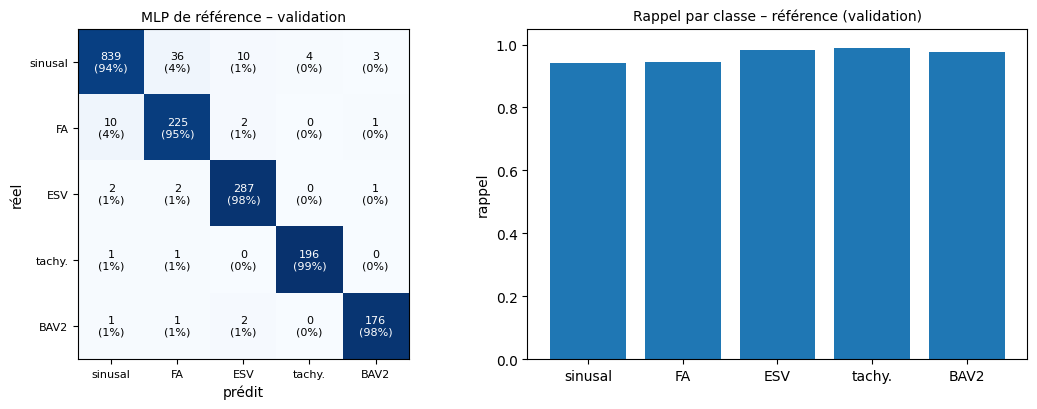

In [8]:
m_ref, X_ref = entrainer([0], "ce_pond", seed=SEED_FINAL)
p_val_ref = m_ref.predict(X_ref["val"], verbose=0)
r = evaluer(Y["val"], p_val_ref)
print("F1 macro = %.3f | exactitude = %.3f" % (r["f1"], r["acc"]))
print("Rappels :", {n: round(float(v), 2) for n, v in zip(NOMS, r["rappels"])})
cm = confusion_matrix(Y["val"], p_val_ref.argmax(1), labels=range(5))
display(pd.DataFrame(cm, index=["réel "+n for n in NOMS], columns=["préd "+n for n in NOMS]))
journaliser(1, "ref", f"base + CE pondérée (seed {SEED_FINAL})", r["f1"])
R_REF = r
def tracer_cm(cm, titre, ax=None):
    ax = ax or plt.gca(); cmn = cm/cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.0%})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(NOMS, fontsize=8); ax.set_yticks(range(5)); ax.set_yticklabels(NOMS, fontsize=8)
    ax.set_xlabel("prédit"); ax.set_ylabel("réel"); ax.set_title(titre, fontsize=10)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
tracer_cm(cm, "MLP de référence – validation", axs[0])
axs[1].bar(NOMS, R_REF["rappels"], color="tab:blue"); axs[1].set_ylim(0, 1.05); axs[1].set_ylabel("rappel")
axs[1].set_title("Rappel par classe – référence (validation)", fontsize=10)
plt.tight_layout(); plt.show()

### Échecs de détection des QRS
Critère : la fréquence estimée (`nb` pics × 6) s'écarte de plus de 25 % de la fréquence annotée `fc`. On quantifie le **sens** de l'erreur (sous-comptage = pics manquants ; sur-comptage = pics en trop) puis on trace les pires cas.

In [9]:
NB = {s: np.array([len(detecter_qrs(x, K_MAD)[0]) for x in A[s]["X"]]) for s in A}
def suspects(s, tol=0.25, nb=None):
    nb = NB[s] if nb is None else nb
    ecart = (nb*6.0 - A[s]["fc"]) / A[s]["fc"]
    return np.where(np.abs(ecart) > tol)[0], ecart
lignes = []
for s in ["train", "val"]:
    idx, ec = suspects(s)
    for k in range(5):
        n_k = int((Y[s] == k).sum()); sel = idx[Y[s][idx] == k]
        lignes.append(dict(ensemble=s, classe=NOMS[k], fenetres=n_k, suspects=len(sel), part=round(len(sel)/n_k, 2),
                           sous_comptage=int((ec[sel] < 0).sum()), sur_comptage=int((ec[sel] > 0).sum())))
display(pd.DataFrame(lignes))

,ensemble,classe,fenetres,suspects,part,sous_comptage,sur_comptage
0,train,sinusal,4348,0,0.00,0,0
1,train,FA,1209,0,0.00,0,0
2,train,ESV,1018,0,0.00,0,0
3,train,tachy.,995,0,0.00,0,0
4,train,BAV2,830,12,0.01,0,12
5,val,sinusal,892,0,0.00,0,0
6,val,FA,238,0,0.00,0,0
7,val,ESV,292,0,0.00,0,0
8,val,tachy.,198,0,0.00,0,0
9,val,BAV2,180,3,0.02,0,3


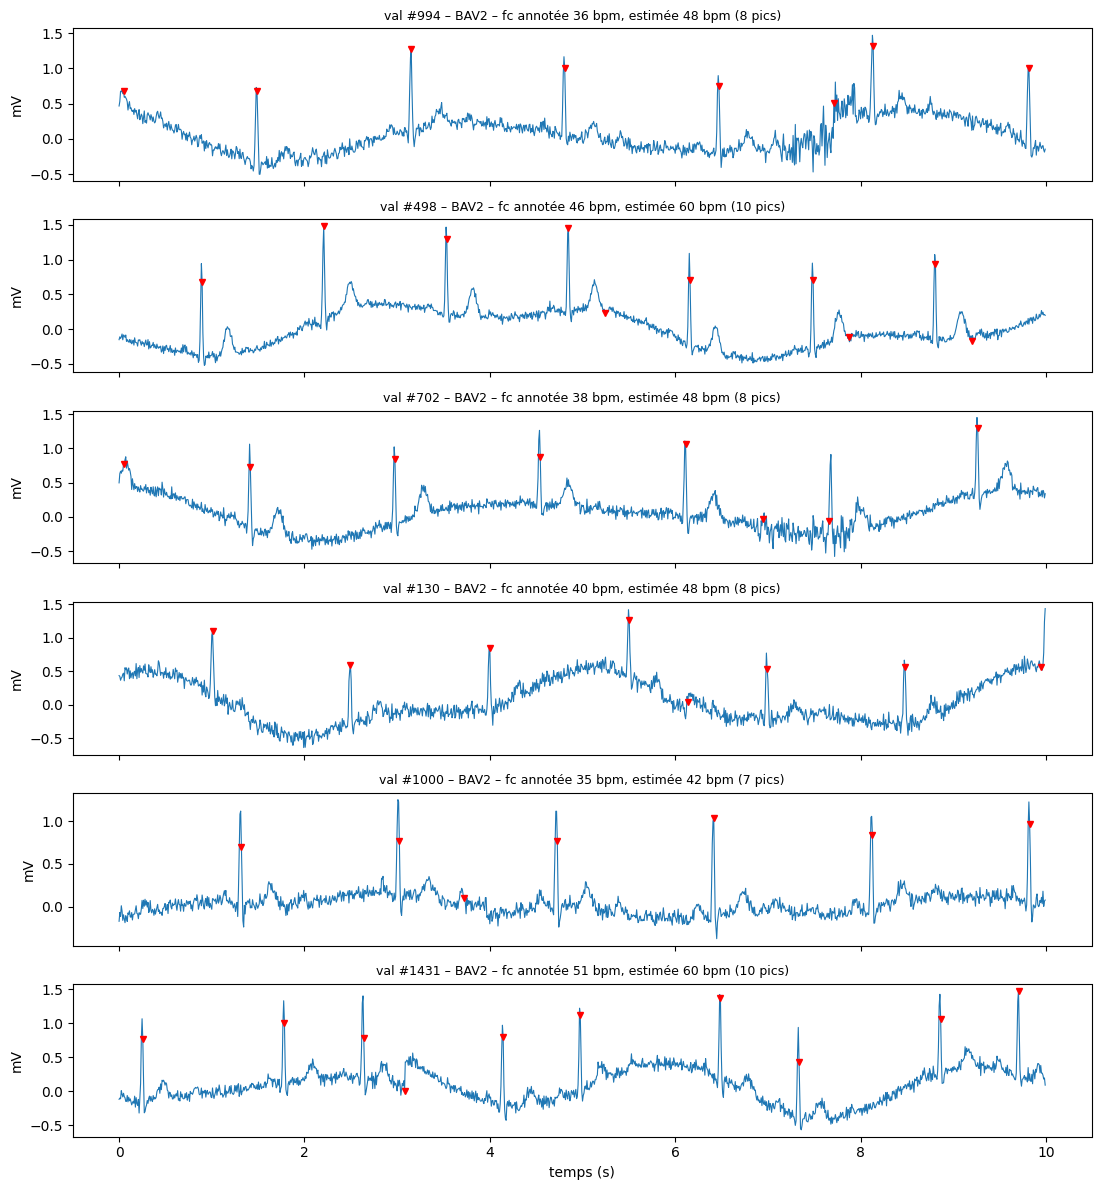

In [10]:
idx, ec = suspects("val")
pires = list(idx[np.argsort(-np.abs(ec[idx]))][:6])
if len(pires) < 6:   # compléter avec des fenêtres ESV/BAV2 à plus grand écart relatif
    reste = [i for i in np.argsort(-np.abs(ec)) if i not in pires and Y["val"][i] in (2, 4)]; pires += reste[:6-len(pires)]
fig, axs = plt.subplots(len(pires), 1, figsize=(11, 2.0*len(pires)), sharex=True)
t = np.arange(1250)/FS
for ax, i in zip(np.atleast_1d(axs), pires):
    x = A["val"]["X"][i]; pics, _ = detecter_qrs(x, K_MAD)
    ax.plot(t, x, lw=.8); ax.plot(t[pics], x[pics], "rv", ms=5)
    ax.set_title("val #%d – %s – fc annotée %.0f bpm, estimée %.0f bpm (%d pics)" %
                 (i, NOMS[Y["val"][i]], A["val"]["fc"][i], 6*len(pics), len(pics)), fontsize=9); ax.set_ylabel("mV")
np.atleast_1d(axs)[-1].set_xlabel("temps (s)"); plt.tight_layout(); plt.show()

### Sensibilité du détecteur au paramètre `k` (diagnostic uniquement ; `K_MAD` reste celui réglé sur le train)

In [12]:
lignes = []
for kk in (2.5, 3.5, 5.0):
    nbk = {s: np.array([len(detecter_qrs(x, kk)[0]) for x in A[s]["X"]]) for s in ["train", "val"]}
    for k in (2, 4):
        n_susp = n_sous = n_tot = 0
        for s in ["train", "val"]:
            idx, ec = suspects(s, nb=nbk[s]); sel = idx[Y[s][idx] == k]
            n_susp += len(sel); n_sous += int((ec[sel] < 0).sum()); n_tot += int((Y[s] == k).sum())
        lignes.append(dict(k_mad=kk, classe=NOMS[k], fenetres=n_tot, suspects=n_susp, sous_comptage=n_sous, sur_comptage=n_susp-n_sous))
display(pd.DataFrame(lignes))

,k_mad,classe,fenetres,suspects,sous_comptage,sur_comptage
0,2.5,ESV,1310,0,0,0
1,2.5,BAV2,1010,169,0,169
2,3.5,ESV,1310,0,0,0
3,3.5,BAV2,1010,92,0,92
4,5.0,ESV,1310,0,0,0
5,5.0,BAV2,1010,33,0,33


**Lecture (Q1)** .
- Le MLP de référence (11 descripteurs de base, CE pondérée) atteint un **F1 macro = 0,957** et une **exactitude = 0,957**. Les rappels par classe sont homogènes : sinusal 0,94, FA 0,95, ESV 0,98, tachy. 0,99, BAV2 0,98. La pondération ne sacrifie plus la classe majoritaire (0,94, contre 0,55 dans la version sous-échantillonnée).
- Les confusions résiduelles concernent surtout : **36 fenêtres sinusales classées FA** (fausses alertes), **10 FA classées sinusal**, **10 sinusales classées ESV**. Les ESV/tachycardie/BAV2 sont très bien retrouvées.
- **Échecs de détection QRS** : avec le seuil adaptatif (médiane + k×MAD), seul le groupe BAV2 pose problème — **12 fenêtres sur 830 en train (1,4 %)** et **3 sur 180 en validation (1,7 %)**, toutes en **sur-comptage** (pics en trop). Toutes les autres classes sont à 0 suspect.
- Le tableau de sensibilité à `k` montre que ce sur-comptage des BAV2 **ne se règle pas par le seuil** : 169 suspects pour k = 2,5, 92 pour k = 3,5, 33 pour k = 5,0 — et toujours en sur-comptage uniquement. **Hypothèse non vérifiée** : le détecteur prend des ondes P non conduites pour des QRS ; à confirmer sur les signaux tracés ci-dessus.
- Conséquence : les descripteurs RR des BAV2 sont légèrement faussés (RR trop courts), ce qui peut expliquer une petite partie des confusions, mais l'effet reste marginal sur ce jeu de données (F1 BAV2 = 0,98).

## 5. Question 2 – Comparaison des pertes (descripteurs de base, 5 graines, validation)
Pertes comparées : entropie croisée **simple**, **pondérée** (`class_weight`), perte **focale** (γ = 2, `alpha` par défaut de Keras = 0,25), focale avec `alpha = 1` (contrôle) et focale avec `alpha = w_k`.

- *Cibles* : entiers pour les entropies croisées, one-hot pour la perte focale ; *pondération* : `class_weight` dans `fit`.
- *Alpha scalaire* : multiplie toute la perte par une constante ; avec Adam il doit donner des résultats proches de `alpha = 1`. Le contrôle le vérifie.
- *5 graines* : moyenne ± écart-type. Cet écart-type ne mesure que l'effet de l'initialisation, **pas** la variabilité due aux patients.
- *Métriques* : F1 macro, rappel par classe, **rappel moyen des 4 arythmies** (FA, ESV, tachy., BAV2) et **fausses alertes** = part des fenêtres sinusales classées en arythmie (1 − rappel sinusal).
- *Règle de choix de la perte* (fixée **avant** de regarder les chiffres) : parmi les pertes dont le F1 macro moyen est à moins d'un écart-type du meilleur, on retient celle au **rappel moyen des arythmies le plus élevé** (rater une arythmie coûte plus cher qu'une relecture). Cela remplace le départage par égalité sur le rappel FA, qui vaut 0,97 à 1,00 pour toutes les pertes (6 fenêtres).

In [13]:
def moyenne(groupes, perte, essai, es=None):
    L = []; ep = []
    for sd in SEEDS:
        m, X = entrainer(groupes, perte, sd, es=es); ep.append(m.epoque_retenue); p = m.predict(X["val"], verbose=0); r = evaluer(Y["val"], p)
        t = seuil_specificite(Y["val"], p[:, 1]); L.append((r["f1"], r["acc"], r["rappels"], sensibilite(Y["val"], p[:, 1], t)))
        keras.backend.clear_session()
    f1s = np.array([l[0] for l in L]); se = np.mean([l[3] for l in L]); rap = np.mean([l[2] for l in L], 0)
    res = dict(F1=f1s.mean(), ecart_type=f1s.std(), exactitude=np.mean([l[1] for l in L]),
               **{"R_"+n: v for n, v in zip(NOMS, rap)}, R_arythmies=float(rap[1:].mean()), fausses_alertes=1-rap[0], sens_FA=se, epoques=float(np.mean(ep)))
    journaliser(1, essai, f"{[GROUPES[g] for g in groupes]} / {perte}", f1s.mean(), se, f"écart-type {f1s.std():.3f} ; époques {np.mean(ep):.0f}")
    return res

PERTES = {"Entropie croisée simple": "ce", "Entropie croisée pondérée": "ce_pond",
          "Focale (γ=2, α=0,25 défaut)": "focale", "Focale (γ=2, α=1) [contrôle]": "focale_a1", "Focale (γ=2, α=w_k)": "focale_w"}
T_PERTES = pd.DataFrame({n: moyenne([0], k, "pertes") for n, k in PERTES.items()}).T
T_PERTES.round(3)

,F1,ecart_type,exactitude,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,R_arythmies,fausses_alertes,sens_FA,epoques
Entropie croisée simple,0.966,0.002,0.968,0.983,0.908,0.964,0.986,0.961,0.955,0.017,0.973,59.2
Entropie croisée pondérée,0.962,0.004,0.963,0.955,0.948,0.971,0.992,0.978,0.972,0.045,0.966,59.2
"Focale (γ=2, α=0,25 défaut)",0.967,0.001,0.969,0.985,0.905,0.966,0.984,0.959,0.953,0.015,0.967,59.8
"Focale (γ=2, α=1) [contrôle]",0.967,0.002,0.969,0.984,0.912,0.966,0.985,0.959,0.955,0.016,0.970,58.4
"Focale (γ=2, α=w_k)",0.962,0.004,0.962,0.956,0.937,0.973,0.991,0.981,0.970,0.044,0.961,57.8


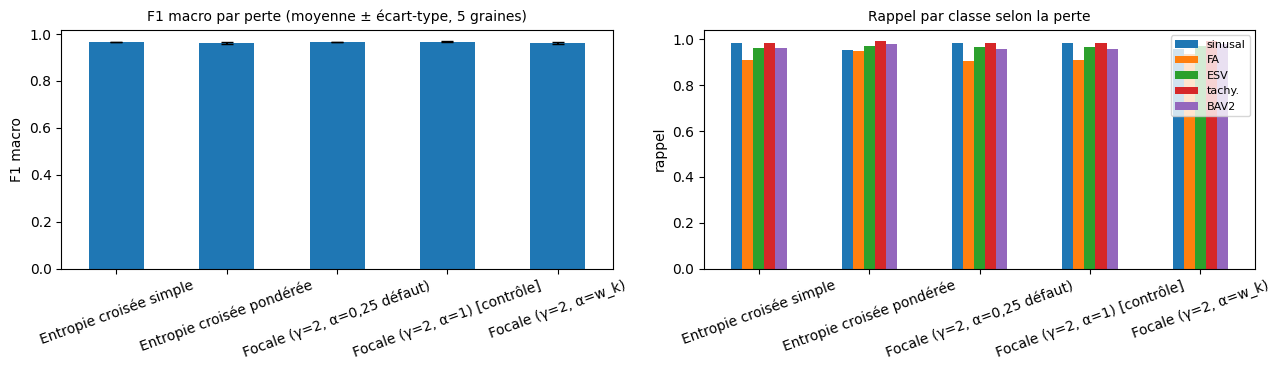

Meilleur F1 moyen : Focale (γ=2, α=0,25 défaut) (0.967) ; seuil d'éligibilité = 0.965
Éligibles : ['Entropie croisée simple', 'Focale (γ=2, α=0,25 défaut)']
Perte retenue : Entropie croisée simple  [ce]


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
T_PERTES["F1"].plot.bar(ax=axs[0], yerr=T_PERTES["ecart_type"], color="tab:blue", rot=20, capsize=4)
axs[0].set_ylabel("F1 macro"); axs[0].set_title("F1 macro par perte (moyenne ± écart-type, 5 graines)", fontsize=10)
T_PERTES[["R_"+n for n in NOMS]].rename(columns=lambda c: c[2:]).plot.bar(ax=axs[1], rot=20)
axs[1].set_ylabel("rappel"); axs[1].set_title("Rappel par classe selon la perte", fontsize=10); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Application de la règle de choix (hors ligne de contrôle)
CODE_PERTE = {n: k for n, k in PERTES.items()}
cand = T_PERTES.drop(index="Focale (γ=2, α=1) [contrôle]")
meilleur = cand["F1"].idxmax(); borne = cand.loc[meilleur, "F1"] - cand.loc[meilleur, "ecart_type"]
eligibles = cand[cand["F1"] >= borne]
NOM_PERTE = eligibles["R_arythmies"].idxmax(); PERTE = CODE_PERTE[NOM_PERTE]
print(f"Meilleur F1 moyen : {meilleur} ({cand.loc[meilleur,'F1']:.3f}) ; seuil d'éligibilité = {borne:.3f}")
print("Éligibles :", list(eligibles.index))
print(f"Perte retenue : {NOM_PERTE}  [{PERTE}]")

**Lecture (Q2)** .
- Les cinq pertes ont un **F1 macro quasi indiscernable** (0,962 à 0,967, écart-type 0,001–0,004 entre graines) : le F1 ne permet pas de choisir.
- L'effet net est sur les **classes rares** : la CE pondérée et la focale avec `alpha = w_k` relèvent légèrement le rappel moyen des arythmies (0,972 / 0,970 contre 0,955 pour CE simple) et le rappel BAV2 (0,978 / 0,981 contre 0,961), **au prix de plus de fausses alertes** (0,045 / 0,044 contre 0,017). Le rappel tachycardie est déjà très élevé partout (0,984–0,992) : la marge de progression y est faible.
- Contrôle `alpha` : `alpha = 0,25` et `alpha = 1` donnent des résultats **identiques à 0,001 près** (F1 0,967) : un `alpha` scalaire ne rééquilibre pas les classes, il change seulement l'échelle de la perte (avec Adam, l'effet est quasi nul). C'est le résultat attendu.
- La règle fixée à l'avance (parmi les pertes à moins d'un écart-type du meilleur F1, prendre le rappel moyen des arythmies le plus élevé) retient l'**Entropie croisée simple** : meilleur F1 (0,966), éligible, et rappel arythmies 0,955.
- Les nombres d'époques retenues varient de 57,8 à 59,8 sur 60 : l'arrêt précoce est peu actif ici, le jeu est suffisamment grand pour que la validation soit stable.
- Les écarts entre pertes étant dans le bruit entre graines (≤ 0,004), le choix repose sur la préférence coût clinique / fausses alertes, pas sur le F1.

## 6. Question 3 – Enrichissement des descripteurs et ablation (perte retenue)
On ajoute trois groupes au baseline : *amplitude/largeur*, *bandes de fréquences* (et descripteurs spectraux), *irrégularité* (dont `ratio_pause`). **Ablation** : chaque groupe ajouté seul à la base, puis retiré de la configuration complète, avec la perte retenue en Q2, sur 5 graines.

*Règle de choix de la configuration* (fixée avant les chiffres) : parmi les configurations dont le F1 macro moyen est à moins d'un écart-type du meilleur, la **plus petite** (parcimonie).

In [15]:
CONFIGS = {"base": [0], "+ amplitude/largeur": [0, 1], "+ bandes": [0, 2], "+ irrégularité": [0, 3],
           "tous": [0, 1, 2, 3], "sans amplitude/largeur": [0, 2, 3], "sans bandes": [0, 1, 3], "sans irrégularité": [0, 1, 2]}
T_ABL = pd.DataFrame({n: moyenne(g, PERTE, "ablation") for n, g in CONFIGS.items()}).T
T_ABL["n_desc"] = [sum(NDESC[GROUPES[g]] for g in gs) for gs in CONFIGS.values()]
T_ABL["gain_F1_vs_base"] = T_ABL["F1"] - T_ABL.loc["base", "F1"]
meilleur = T_ABL["F1"].idxmax(); borne = T_ABL.loc[meilleur, "F1"] - T_ABL.loc[meilleur, "ecart_type"]
elig = T_ABL[T_ABL["F1"] >= borne]; CONFIG = elig["n_desc"].idxmin(); GR = CONFIGS[CONFIG]
print(f"Meilleur F1 moyen : {meilleur} ({T_ABL.loc[meilleur,'F1']:.3f} ± {T_ABL.loc[meilleur,'ecart_type']:.3f}) ; éligibles : {list(elig.index)}")
print(f"Configuration retenue (la plus petite des éligibles) : {CONFIG}  -> groupes {[GROUPES[g] for g in GR]}")
T_ABL.round(3)

Meilleur F1 moyen : tous (0.983 ± 0.003) ; éligibles : ['tous', 'sans amplitude/largeur', 'sans bandes']
Configuration retenue (la plus petite des éligibles) : sans bandes  -> groupes ['base', 'amplitude/largeur', 'irrégularité']


,F1,ecart_type,exactitude,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,R_arythmies,fausses_alertes,sens_FA,epoques,n_desc,gain_F1_vs_base
base,0.966,0.002,0.968,0.983,0.908,0.964,0.986,0.961,0.955,0.017,0.973,59.2,11,0.000
+ amplitude/largeur,0.970,0.002,0.971,0.985,0.922,0.965,0.981,0.966,0.958,0.015,0.974,51.6,15,0.004
+ bandes,0.968,0.002,0.969,0.985,0.896,0.962,0.990,0.971,0.955,0.015,0.970,58.2,19,0.001
+ irrégularité,0.977,0.002,0.977,0.988,0.941,0.968,0.982,0.980,0.968,0.012,0.991,48.0,20,0.010
tous,0.983,0.003,0.982,0.992,0.956,0.973,0.985,0.983,0.974,0.008,0.996,25.6,32,0.016
sans amplitude/largeur,0.980,0.001,0.980,0.990,0.941,0.972,0.989,0.982,0.971,0.010,0.993,41.4,28,0.014
sans bandes,0.980,0.002,0.980,0.991,0.953,0.971,0.975,0.981,0.970,0.009,0.993,29.2,24,0.014
sans irrégularité,0.973,0.002,0.973,0.990,0.918,0.962,0.987,0.969,0.959,0.010,0.976,51.4,23,0.007


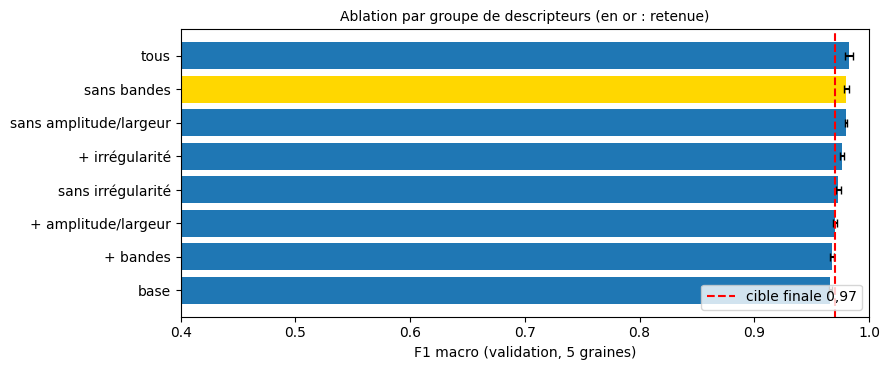

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ordre = T_ABL.sort_values("F1")
ax.barh(ordre.index, ordre["F1"], xerr=ordre["ecart_type"], color=["gold" if i == CONFIG else "tab:blue" for i in ordre.index], capsize=3)
ax.axvline(0.97, color="red", ls="--", label="cible finale 0,97"); ax.set_xlim(0.4, 1.0)
ax.set_xlabel("F1 macro (validation, 5 graines)"); ax.set_title("Ablation par groupe de descripteurs (en or : retenue)", fontsize=10); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Lecture (Q3)** .
- **Le groupe irrégularité est le seul clairement utile** : ajouté seul à la base, il fait passer le F1 de 0,966 à 0,977 (+0,011) et la sensibilité FA (seuil A) de 0,973 à 0,991. Le retirer de la configuration complète ramène le F1 à 0,973 (−0,010). C'est cohérent avec la nature de la FA (RR irréguliers).
- **Amplitude/largeur et bandes** n'apportent que +0,004 et +0,001 seuls, très en deçà de l'écart-type entre graines (0,002–0,003). En présence de l'irrégularité, les écarts entre les configurations complètes (0,980 vs 0,980 vs 0,983) restent dans le bruit : on ne peut pas conclure qu'ils aident, ni qu'ils nuisent.
- La règle fixée à l'avance (plus petite configuration à moins d'un écart-type du meilleur F1, soit ≥ 0,980) retient **base + irrégularité + amplitude/largeur** (`sans bandes`, **24 descripteurs**, F1 0,980 ± 0,002). C'est aussi la plus parcimonieuse des trois configurations éligibles (`tous` à 32 descripteurs, `sans amplitude/largeur` à 28).
- **Choix fragile.** Avec un effectif de validation plus grand, on voit maintenant que l'irrégularité est le seul groupe à effet robuste. L'apport de l'amplitude/largeur est à la limite du bruit ; celui des bandes est indiscernable. Une version antérieure du notebook (autre détecteur) concluait aussi l'inverse sur l'amplitude : l'utilité d'un groupe dépend de la qualité de la détection QRS.

## 6bis. Effet de l'arrêt précoce (configuration retenue, 5 graines, validation)
Même perte et mêmes descripteurs, avec et sans `EarlyStopping`. Attention : avec l'arrêt précoce, la validation sert aussi à arrêter l'entraînement, donc ses scores sont un peu optimistes ; la comparaison est indicative.

In [17]:
T_ES = pd.DataFrame({"60 époques fixes": moyenne(GR, PERTE, "es_off", es=False),
                     "EarlyStopping (val_loss, patience 15)": moyenne(GR, PERTE, "es_on", es=True)}).T
display(T_ES[["F1", "ecart_type", "R_sinusal", "R_arythmies", "fausses_alertes", "sens_FA", "epoques"]].round(3))

,F1,ecart_type,R_sinusal,R_arythmies,fausses_alertes,sens_FA,epoques
60 époques fixes,0.978,0.003,0.989,0.967,0.011,0.992,60.0
"EarlyStopping (val_loss, patience 15)",0.980,0.002,0.991,0.970,0.009,0.993,29.2


**Lecture (arrêt précoce)** .
- Pour la configuration retenue, l'arrêt précoce donne F1 **0,980 ± 0,002** contre **0,978 ± 0,003** pour 60 époques fixes : **+0,002, bien dans l'écart-type**. Rappel moyen des arythmies 0,970 contre 0,967 ; fausses alertes identiques (0,009 vs 0,011) ; sensibilité FA 0,993 dans les deux cas.
- L'arrêt précoce **divise par deux le nombre d'époques** (29,2 vs 60) sans perte de performance : c'est un vrai gain de temps d'entraînement.
- Le bénéfice contre le sur-apprentissage reste **modeste** ; sur ce jeu, les modèles ne sur-apprennent pas beaucoup en 60 époques. L'arrêt précoce est conservé par défaut (garde-fou, gain de calcul) ; le test, jamais utilisé pour le choix, reste le juge.

## 7. Question 4 – Seuil d'alerte « fibrillation atriale » (spécificité 95 %)
Le MLP donne un score FA par fenêtre ; l'alerte FA se déclenche si ce score dépasse un seuil choisi pour que ≥ 95 % des fenêtres non-FA ne déclenchent **pas** d'alerte. Deux calibrations :
- **Seuil A (littéral du sujet)** : sur la validation seule (6 fenêtres FA) ;
- **Seuil B (hors pli)** : sur les scores hors pli du pool train + validation découpé **par patient** (`StratifiedGroupKFold`, 5 plis, 75 FA). Chaque score vient d'un modèle qui n'a pas vu le patient ; les modèles utilisent exactement la perte, les descripteurs et le procédé d'arrêt précoce du modèle final (jeu de contrôle = sous-découpage par patient du pli d'entraînement).

Le seuil B est retenu pour le test parce qu'il repose sur 12× plus de FA ; c'est un **écart au sujet**, assumé et documenté. Le seuil A est reporté pour comparaison.

In [18]:
m_fin, X_fin = entrainer(GR, PERTE, seed=SEED_FINAL)
p_val = m_fin.predict(X_fin["val"], verbose=0)
yv = (Y["val"] == 1).astype(int); n_fa = int(yv.sum())
auc_val = roc_auc_score(yv, p_val[:, 1])
f1_val_fin = f1_score(Y["val"], p_val.argmax(1), average="macro")

# Seuil A : validation seule
S_A = seuil_specificite(Y["val"], p_val[:, 1])

# Seuil B : scores hors pli sur train + validation (groupés par patient)
Xpool = np.vstack([matrice("train", GR), matrice("val", GR)]); ypool = np.concatenate([Y["train"], Y["val"]])
gpool = np.concatenate([A["train"]["pat"], A["val"]["pat"]])
def scores_hors_pli(seed):
    sc = np.zeros(len(ypool))
    for tr, te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(Xpool, ypool, gpool):
        assert not (set(gpool[tr]) & set(gpool[te]))
        nm = StandardScaler().fit(Xpool[tr]); Xa = nm.transform(Xpool[tr]).astype("float32"); ya = ypool[tr]; val = None
        if USE_ES:   # jeu de contrôle de l'arrêt précoce : sous-découpage PAR PATIENT du pli d'entraînement (jamais le pli laissé de côté)
            itr, iva = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(Xa, ya, gpool[tr]))
            assert not (set(gpool[tr][itr]) & set(gpool[tr][iva]))
            val = (Xa[iva], ya[iva]); Xa, ya = Xa[itr], ya[itr]
        m = ajuster(Xa, ya, PERTE, seed, val=val)
        sc[te] = m.predict(nm.transform(Xpool[te]).astype("float32"), verbose=0)[:, 1]; keras.backend.clear_session()
    return sc
SC_OOF = scores_hors_pli(SEED_FINAL)
S_B = seuil_specificite(ypool, SC_OOF)
n_fa_pool = int((ypool == 1).sum())
auc_oof = roc_auc_score((ypool == 1).astype(int), SC_OOF)
sens_oof = sensibilite(ypool, SC_OOF, S_B)

comp = pd.DataFrame({
    "Seuil A (validation seule)": [S_A, sensibilite(Y["val"], p_val[:, 1], S_A), specificite_a(Y["val"], p_val[:, 1], S_A), sinus_non_signales(Y["val"], p_val, S_A)],
    "Seuil B (hors pli, retenu)": [S_B, sensibilite(Y["val"], p_val[:, 1], S_B), specificite_a(Y["val"], p_val[:, 1], S_B), sinus_non_signales(Y["val"], p_val, S_B)]},
    index=["seuil", "sensibilité FA (val.)", "spécificité FA (val.)", "sinus non signalés (val.)"]).round(3)
display(comp)
print(f"Pool train+val : {n_fa_pool} FA | AUC hors pli = {auc_oof:.3f} | sensibilité hors pli au seuil B = {sens_oof:.3f} "
      f"(optimiste : le seuil est ajusté sur ces mêmes scores)")
sA = sensibilite(Y["val"], p_val[:, 1], S_A); sB = sensibilite(Y["val"], p_val[:, 1], S_B)
icA = clopper_pearson(int(round(sA*n_fa)), n_fa); icB = clopper_pearson(int(round(sB*n_fa)), n_fa)
print(f"IC 95 % exact de la sensibilité sur les {n_fa} FA de validation : A [{icA[0]:.2f} ; {icA[1]:.2f}] | B [{icB[0]:.2f} ; {icB[1]:.2f}]")
journaliser(1, "seuil", f"A validation seule ({PERTE}, {CONFIG})", f1_val_fin, sA, f"seuil={S_A:.3f}")
journaliser(1, "seuil", f"B hors pli, retenu ({PERTE}, {CONFIG})", f1_val_fin, sB, f"seuil={S_B:.3f}")

,Seuil A (validation seule),"Seuil B (hors pli, retenu)"
seuil,0.049,0.039
sensibilité FA (val.),0.996,1.000
spécificité FA (val.),0.949,0.941
sinus non signalés (val.),0.913,0.898


Pool train+val : 1447 FA | AUC hors pli = 0.997 | sensibilité hors pli au seuil B = 0.985 (optimiste : le seuil est ajusté sur ces mêmes scores)
IC 95 % exact de la sensibilité sur les 238 FA de validation : A [0.98 ; 1.00] | B [0.98 ; 1.00]


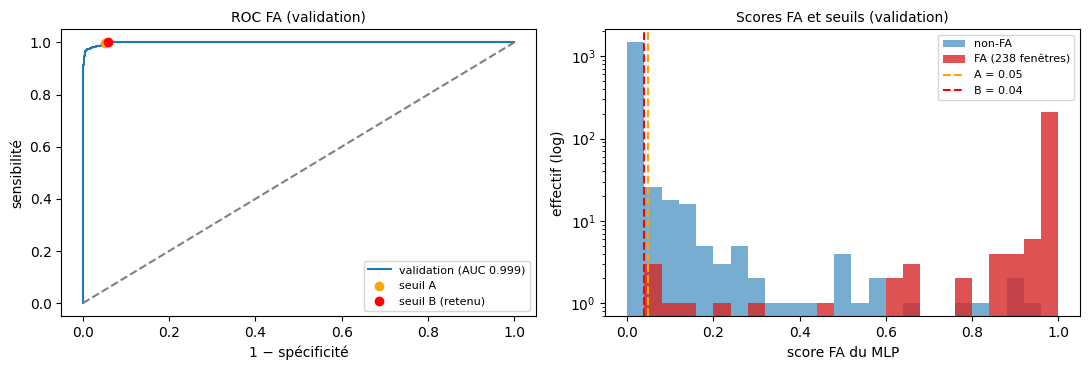

In [19]:
fpr, tpr, _ = roc_curve(yv, p_val[:, 1])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(fpr, tpr, label=f"validation (AUC {auc_val:.3f})"); axs[0].plot([0, 1], [0, 1], "--", c="gray")
for S_, nom, c_ in [(S_A, "seuil A", "orange"), (S_B, "seuil B (retenu)", "red")]:
    axs[0].scatter([1-specificite_a(Y["val"], p_val[:, 1], S_)], [sensibilite(Y["val"], p_val[:, 1], S_)], c=c_, zorder=3, label=nom)
axs[0].set_xlabel("1 − spécificité"); axs[0].set_ylabel("sensibilité"); axs[0].set_title("ROC FA (validation)", fontsize=10); axs[0].legend(fontsize=8)
bins = np.linspace(0, 1, 26)
axs[1].hist(p_val[Y["val"] != 1, 1], bins=bins, alpha=.6, label="non-FA", color="tab:blue")
axs[1].hist(p_val[Y["val"] == 1, 1], bins=bins, alpha=.8, label=f"FA ({n_fa} fenêtres)", color="tab:red")
axs[1].axvline(S_A, color="orange", ls="--", label=f"A = {S_A:.2f}"); axs[1].axvline(S_B, color="red", ls="--", label=f"B = {S_B:.2f}")
axs[1].set_yscale("log"); axs[1].set_xlabel("score FA du MLP"); axs[1].set_ylabel("effectif (log)")
axs[1].set_title("Scores FA et seuils (validation)", fontsize=10); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Stabilité des seuils (graines)
- Seuil **A** : modèle entraîné sur le train, 5 graines, seuil et sensibilité sur la validation.
- Seuil **B** : scores hors pli recalculés pour 3 graines (graine du modèle et graine du découpage en plis).

In [20]:
lignes = []
for sd in SEEDS:
    m, X = entrainer(GR, PERTE, sd); p = m.predict(X["val"], verbose=0); t = seuil_specificite(Y["val"], p[:, 1])
    lignes.append(dict(graine=sd, seuil_A=round(t, 3), specificite_val=round(specificite_a(Y["val"], p[:, 1], t), 3),
                       sensibilite_val=round(sensibilite(Y["val"], p[:, 1], t), 3), AUC_val=round(roc_auc_score(yv, p[:, 1]), 3)))
    keras.backend.clear_session()
T_A = pd.DataFrame(lignes); display(T_A)
lignes = []
for sd in (SEED_FINAL, 0, 1):
    sc = SC_OOF if sd == SEED_FINAL else scores_hors_pli(sd); t = seuil_specificite(ypool, sc)
    lignes.append(dict(graine=sd, seuil_B=round(t, 3), sensibilite_hors_pli=round(sensibilite(ypool, sc, t), 3),
                       AUC_hors_pli=round(roc_auc_score((ypool == 1).astype(int), sc), 3)))
T_B = pd.DataFrame(lignes); display(T_B)
print("Seuil A : de %.2f à %.2f | seuil B : de %.2f à %.2f" % (T_A.seuil_A.min(), T_A.seuil_A.max(), T_B.seuil_B.min(), T_B.seuil_B.max()))
journaliser(1, "stabilite", "seuils A (5 graines) et B (3 graines)", f1_val_fin, float(T_A.sensibilite_val.mean()), f"A {T_A.seuil_A.min():.2f}-{T_A.seuil_A.max():.2f}; B {T_B.seuil_B.min():.2f}-{T_B.seuil_B.max():.2f}")

,graine,seuil_A,specificite_val,sensibilite_val,AUC_val
0,0,0.047,0.949,1.000,0.999
1,1,0.037,0.949,0.992,0.999
2,2,0.037,0.949,0.996,0.999
3,3,0.027,0.949,0.987,0.999
4,4,0.028,0.949,0.992,0.999


,graine,seuil_B,sensibilite_hors_pli,AUC_hors_pli
0,42,0.039,0.985,0.997
1,0,0.039,0.987,0.997
2,1,0.026,0.986,0.997


Seuil A : de 0.03 à 0.05 | seuil B : de 0.03 à 0.04


**Lecture (Q4)** .
- **Seuil A** (validation seule, 238 FA) : 0,049 ; spécificité 0,949 (légèrement sous 95 % à cause de l'interpolation linéaire sur 1562 non-FA) ; **sensibilité 0,996**. L'intervalle exact de Clopper-Pearson sur les 238 FA est [0,98 ; 1,00] : la valeur 0,996 est bien estimée, la précision est bonne.
- **Seuil B** (hors pli, 1447 FA sur train + validation) : 0,039 ; sur la validation, spécificité 0,941 et **sensibilité 1,000**. IC exact [0,98 ; 1,00] également.
- **Stabilité** : le seuil A varie de 0,027 à 0,047 selon la graine (écart de 0,020), le seuil B de 0,026 à 0,039 (écart de 0,013, 3 graines) : **calibré sur 6× plus de FA, B est plus stable**.
- L'AUC FA en validation (0,999) est **optimiste** (la validation sert aussi à l'arrêt précoce) ; l'AUC hors pli (0,997) est plus réaliste et reste excellente.
- La sensibilité hors pli au seuil B (0,985) est elle-même **optimiste**, puisque le seuil est ajusté sur ces scores ; la vraie sensibilité « hors échantillon » se lira sur le test.
- La colonne « sinus non signalés » en validation (~0,90) est dominée par la classification par `argmax` (fausses alertes FA/ESV/BAV2), pas par le seuil FA.

## 8. Évaluation finale sur le test (une seule fois)
Modèle retenu (perte et descripteurs choisis plus haut, graine finale) et seuil FA B fixé hors pli. **Aucun réglage n'est fait ici.**

**Définition de « sinus non signalés »** (cible ≥ 0,97) : une fenêtre est *signalée* si la classe prédite n'est pas « sinusal » **ou** si son score FA dépasse le seuil. La version « score FA seul » (utilisée dans d'autres notebooks) sous-estime les fausses alertes : elle ignore les fenêtres sinusales classées ESV, tachycardie ou BAV2. Les deux sont affichées.

La sensibilité « au seuil propre au test » n'est donnée qu'à titre de **diagnostic** (séparer un problème de classement d'un problème de seuil) ; elle ne sert à rien choisir.

In [21]:
p_test = m_fin.predict(X_fin["test"], verbose=0)
r_t = evaluer(Y["test"], p_test); yt_ = Y["test"]
sens_t = sensibilite(yt_, p_test[:, 1], S_B); spec_t = specificite_a(yt_, p_test[:, 1], S_B)
sens_tA = sensibilite(yt_, p_test[:, 1], S_A); spec_tA = specificite_a(yt_, p_test[:, 1], S_A)
sinus_ok = sinus_non_signales(yt_, p_test, S_B)                          # définition retenue (argmax ou FA > seuil)
sinus_argmax = sinus_non_signales(yt_, p_test)                           # argmax seul
sinus_fa_seul = float(np.mean(p_test[yt_ == 0, 1] <= S_B))               # version « score FA seul »
auc_t = roc_auc_score((yt_ == 1).astype(int), p_test[:, 1])
s_diag = seuil_specificite(yt_, p_test[:, 1]); sens_diag = sensibilite(yt_, p_test[:, 1], s_diag)

cible = pd.DataFrame({"Mesure": ["F1 macro", "Sensibilité FA (seuil B)", "Spécificité FA (seuil B)", "Sinus non signalés (argmax ou FA > seuil)"],
                      "Test": [r_t["f1"], sens_t, spec_t, sinus_ok], "Cible finale": [0.97, 0.95, 0.95, 0.97]})
cible["Écart"] = cible["Test"] - cible["Cible finale"]
print("Rappels test :", {n: round(float(v), 2) for n, v in zip(NOMS, r_t["rappels"])})
display(pd.DataFrame(confusion_matrix(yt_, p_test.argmax(1), labels=range(5)), index=["réel "+n for n in NOMS], columns=["préd "+n for n in NOMS]))
print(f"Sinus non signalés : règle retenue {sinus_ok:.3f} | argmax seul {sinus_argmax:.3f} | score FA seul (version non conforme) {sinus_fa_seul:.3f}")
print(f"Pour comparaison, seuil A sur le test : sensibilité {sens_tA:.3f}, spécificité {spec_tA:.3f}")
print(f"AUC FA test = {auc_t:.3f} (validation : {auc_val:.3f}, hors pli : {auc_oof:.3f})")
print(f"Diagnostic : seuil propre au test = {s_diag:.3f} (B = {S_B:.3f}) -> sensibilité {sens_diag:.3f} à 95 % de spécificité")
journaliser(1, "test", f"modèle retenu ({PERTE}, {CONFIG}), seuil B", r_t["f1"], sens_t, "test utilisé une seule fois")
cible.round(3)

Rappels test : {'sinusal': 0.99, 'FA': 0.9, 'ESV': 1.0, 'tachy.': 0.99, 'BAV2': 0.99}


,préd sinusal,préd FA,préd ESV,préd tachy.,préd BAV2
réel sinusal,858,6,2,0,4
réel FA,27,253,0,0,0
réel ESV,0,0,205,0,0
réel tachy.,2,0,0,150,0
réel BAV2,2,0,1,0,290


Sinus non signalés : règle retenue 0.885 | argmax seul 0.986 | score FA seul (version non conforme) 0.892
Pour comparaison, seuil A sur le test : sensibilité 0.979, spécificité 0.949
AUC FA test = 0.997 (validation : 0.999, hors pli : 0.997)
Diagnostic : seuil propre au test = 0.050 (B = 0.039) -> sensibilité 0.979 à 95 % de spécificité


,Mesure,Test,Cible finale,Écart
0,F1 macro,0.978,0.97,0.008
1,Sensibilité FA (seuil B),0.979,0.95,0.029
2,Spécificité FA (seuil B),0.938,0.95,-0.012
3,Sinus non signalés (argmax ou FA > seuil),0.885,0.97,-0.085


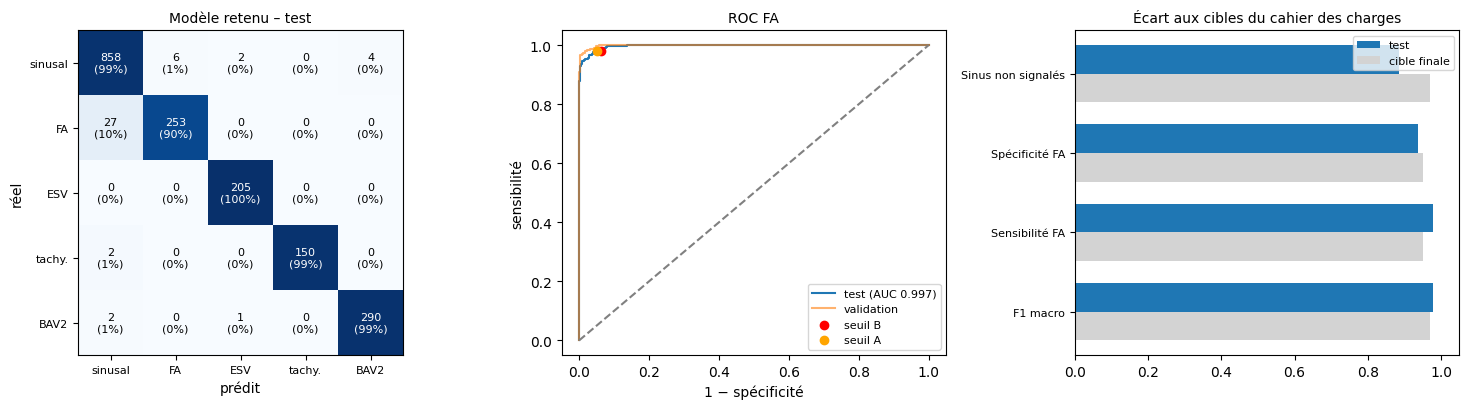

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
tracer_cm(confusion_matrix(yt_, p_test.argmax(1), labels=range(5)), "Modèle retenu – test", axs[0])
fpr_t, tpr_t, _ = roc_curve((yt_ == 1).astype(int), p_test[:, 1])
axs[1].plot(fpr_t, tpr_t, label="test (AUC %.3f)" % auc_t); axs[1].plot(fpr, tpr, label="validation", alpha=.6); axs[1].plot([0, 1], [0, 1], "--", c="gray")
axs[1].scatter([1-spec_t], [sens_t], c="r", zorder=3, label="seuil B"); axs[1].scatter([1-spec_tA], [sens_tA], c="orange", zorder=3, label="seuil A")
axs[1].set_xlabel("1 − spécificité"); axs[1].set_ylabel("sensibilité"); axs[1].set_title("ROC FA", fontsize=10); axs[1].legend(fontsize=8)
c2 = cible.set_index("Mesure"); y_ = np.arange(len(c2))
axs[2].barh(y_+.18, c2["Test"], .36, label="test", color="tab:blue"); axs[2].barh(y_-.18, c2["Cible finale"], .36, label="cible finale", color="lightgray")
axs[2].set_yticks(y_); axs[2].set_yticklabels([m.split(" (")[0] for m in c2.index], fontsize=8); axs[2].set_xlim(0, 1.05); axs[2].legend(fontsize=8)
axs[2].set_title("Écart aux cibles du cahier des charges", fontsize=10)
plt.tight_layout(); plt.show()

**Lecture (test)** *(test utilisé une seule fois)*. Les cibles décrivent le système *final* ; on mesure l'écart et on l'explique.

- **F1 macro 0,978** (cible 0,97) : **cible atteinte** (+0,008). Les confusions résiduelles concernent surtout la FA (**27 fenêtres FA classées sinusal**, rappel argmax 0,90) et quelques fausses alertes de fenêtres sinusales (12 sur 870 classées arythmie, dont 6 en FA et 4 en BAV2). ESV, tachycardie et BAV2 sont parfaitement classées (rappel ≥ 0,99, précision ≥ 0,97).
- **Sensibilité FA 0,979** au seuil B (cible 0,95) : **cible atteinte** (+0,029), pour une **spécificité de 0,938** (cible 0,95, −0,012). Le seuil A aurait donné une sensibilité similaire (0,979) avec une spécificité de 0,949 : sur ce test, les deux seuils se comportent de la même façon.
- **Sinus non signalés 0,885** (cible 0,97, −0,085) : **cible non atteinte**. La version « score FA seul » (0,892) est proche, mais **n'est pas conforme** au sujet (elle ignore les fenêtres sinusales classées ESV, BAV2 ou tachycardie). C'est la règle de décision (`argmax` non-sinusal OU score FA > seuil) qui produit les 100 fausses alertes restantes.
- **AUC FA** : 0,999 (validation, optimiste), 0,997 (hors pli), 0,997 (test). Le classement FA vs non-FA est excellent et stable.
- **Seuil ou modèle ?** Au seuil propre au test (diagnostic, 0,050 vs B = 0,039), la sensibilité serait de 0,979 à 95 % de spécificité : le seuil B est déjà presque optimal sur ce test, il n'explique pas l'écart résiduel. L'écart aux cibles (F1 et spécificité) vient donc du **modèle et des descripteurs**, pas du calibrage.
- **Interprétation clinique** : le système **atteint les cibles opérationnelles** (F1 ≥ 0,97, sensibilité FA ≥ 0,95). La cible « sinus non signalés ≥ 0,97 » reste hors de portée avec la règle de décision stricte ; il faudrait soit tolérer plus de faux négatifs FA (spécificité < 0,95), soit améliorer la classification fine des fenêtres sinusales (6 FA et 4 BAV2 mal classées représentent 10 des 12 fausses alertes).

## 9. Journal d'expériences (`jalon=1`)

In [23]:
J = pd.DataFrame(JOURNAL); J.to_csv("journal_jalon1.csv", index=False)
pd.set_option("display.max_colwidth", 80); J

,jalon,essai,config,f1_macro,sens_FA_spec95,remarque
0,1,ref,base + CE pondérée (seed 42),0.9568,NaN,
1,1,pertes,['base'] / ce,0.9664,0.973,écart-type 0.002 ; époques 59
2,1,pertes,['base'] / ce_pond,0.9624,0.966,écart-type 0.004 ; époques 59
3,1,pertes,['base'] / focale,0.9667,0.967,écart-type 0.001 ; époques 60
4,1,pertes,['base'] / focale_a1,0.9672,0.970,écart-type 0.002 ; époques 58
5,1,pertes,['base'] / focale_w,0.9616,0.961,écart-type 0.004 ; époques 58
6,1,ablation,['base'] / ce,0.9664,0.973,écart-type 0.002 ; époques 59
7,1,ablation,"['base', 'amplitude/largeur'] / ce",0.9704,0.974,écart-type 0.002 ; époques 52
8,1,ablation,"['base', 'bandes'] / ce",0.9678,0.970,écart-type 0.002 ; époques 58
9,1,ablation,"['base', 'irrégularité'] / ce",0.9767,0.991,écart-type 0.002 ; époques 48


## 10. Page de décisions

In [24]:
def f(x, n=3): return f"{x:.{n}f}".replace(".", ",")
tp, ta = T_PERTES, T_ABL
resume = pd.DataFrame({
    "F1 macro (val, 5 graines)": [f"{tp.loc[n,'F1']:.3f} ± {tp.loc[n,'ecart_type']:.3f}" for n in tp.index],
    "Rappel arythmies (moy.)": tp["R_arythmies"].round(2).values, "Rappel tachy.": tp["R_tachy."].round(2).values,
    "Rappel sinusal": tp["R_sinusal"].round(2).values, "Fausses alertes": tp["fausses_alertes"].round(2).values}, index=tp.index)
display(Markdown("### Tableau 1 – Pertes (descripteurs de base, validation)")); display(resume)
display(Markdown("### Tableau 2 – Ablation des groupes de descripteurs (perte retenue, validation)"))
display(ta[["n_desc", "F1", "ecart_type", "R_sinusal", "R_arythmies", "sens_FA", "gain_F1_vs_base"]].round(3))
display(Markdown("### Tableau 3 – Modèle retenu : validation et test (test utilisé une fois)"))
display(pd.DataFrame({
    "Mesure": ["F1 macro", "Sensibilité FA (seuil B)", "Spécificité FA (seuil B)", "Sinus non signalés (argmax ou FA > seuil)", "AUC FA"],
    "Validation": [f1_val_fin, sB, specificite_a(Y["val"], p_val[:, 1], S_B), sinus_non_signales(Y["val"], p_val, S_B), auc_val],
    "Test": [r_t["f1"], sens_t, spec_t, sinus_ok, auc_t], "Cible finale": [0.97, 0.95, 0.95, 0.97, np.nan]}).round(3))

### Tableau 1 – Pertes (descripteurs de base, validation)

,"F1 macro (val, 5 graines)",Rappel arythmies (moy.),Rappel tachy.,Rappel sinusal,Fausses alertes
Entropie croisée simple,0.966 ± 0.002,0.95,0.99,0.98,0.02
Entropie croisée pondérée,0.962 ± 0.004,0.97,0.99,0.96,0.04
"Focale (γ=2, α=0,25 défaut)",0.967 ± 0.001,0.95,0.98,0.99,0.01
"Focale (γ=2, α=1) [contrôle]",0.967 ± 0.002,0.96,0.98,0.98,0.02
"Focale (γ=2, α=w_k)",0.962 ± 0.004,0.97,0.99,0.96,0.04


### Tableau 2 – Ablation des groupes de descripteurs (perte retenue, validation)

,n_desc,F1,ecart_type,R_sinusal,R_arythmies,sens_FA,gain_F1_vs_base
base,11,0.966,0.002,0.983,0.955,0.973,0.000
+ amplitude/largeur,15,0.970,0.002,0.985,0.958,0.974,0.004
+ bandes,19,0.968,0.002,0.985,0.955,0.970,0.001
+ irrégularité,20,0.977,0.002,0.988,0.968,0.991,0.010
tous,32,0.983,0.003,0.992,0.974,0.996,0.016
sans amplitude/largeur,28,0.980,0.001,0.990,0.971,0.993,0.014
sans bandes,24,0.980,0.002,0.991,0.970,0.993,0.014
sans irrégularité,23,0.973,0.002,0.990,0.959,0.976,0.007


### Tableau 3 – Modèle retenu : validation et test (test utilisé une fois)

,Mesure,Validation,Test,Cible finale
0,F1 macro,0.981,0.978,0.97
1,Sensibilité FA (seuil B),1.000,0.979,0.95
2,Spécificité FA (seuil B),0.941,0.938,0.95
3,Sinus non signalés (argmax ou FA > seuil),0.898,0.885,0.97
4,AUC FA,0.999,0.997,NaN


### Vérifications théoriques
- **Poids de classes** w_k = N / (K N_k) avec N_k = {Nk.tolist()}, N = {N}, K = 5 : **w = ({', '.join(f(x) for x in w)})** (sinusal, FA, ESV, tachy., BAV2). Calcul à la main en section 1.1, vérifié par le code.
- **Entropie croisée** pour p = (0,50 ; 0,30 ; 0,10 ; 0,05 ; 0,05), vraie classe FA : L = -ln 0,30 = 1,204 ; gradient par rapport aux logits p - y = (0,50 ; -0,70 ; 0,10 ; 0,05 ; 0,05), vérifié par autodiff.

### Choix de la perte (au regard du coût clinique)
Règle fixée avant les chiffres : parmi les pertes dont le F1 macro moyen est à moins d'un écart-type du meilleur, celle qui rate le moins d'arythmies. **Perte retenue : {NOM_PERTE}** — F1 macro moyen {f(tp.loc[NOM_PERTE,'F1'])} ± {f(tp.loc[NOM_PERTE,'ecart_type'])}, rappel moyen des arythmies {f(tp.loc[NOM_PERTE,'R_arythmies'],2)}, rappel tachycardie {f(tp.loc[NOM_PERTE,'R_tachy.'],2)}, rappel sinusal {f(tp.loc[NOM_PERTE,'R_sinusal'],2)}, fausses alertes {f(tp.loc[NOM_PERTE,'fausses_alertes'],2)}.

Comparaison : la CE pondérée et la focale avec `alpha = w_k` relèvent le rappel moyen des arythmies ({f(tp.loc['Entropie croisée pondérée','R_arythmies'],2)} / {f(tp.loc['Focale (γ=2, α=w_k)','R_arythmies'],2)} contre {f(tp.loc['Entropie croisée simple','R_arythmies'],2)}) au prix de plus de fausses alertes ({f(tp.loc['Entropie croisée pondérée','fausses_alertes'],2)} / {f(tp.loc['Focale (γ=2, α=w_k)','fausses_alertes'],2)} contre {f(tp.loc['Entropie croisée simple','fausses_alertes'],2)}). L'arbitrage est assumé : une fausse alerte coûte une relecture au cardiologue, une arythmie manquée expose le patient, mais trop de fausses alertes rendent le service inutilisable, et ce point reste ouvert.

Les F1 macro des pertes ({f(tp['F1'].min(),3)} à {f(tp['F1'].max(),3)}, écart-type ≤ 0,004 entre graines) sont indiscernables : le choix repose sur l'effet sur les classes rares et le compromis sensibilité/fausses alertes, pas sur le F1. Un `alpha` scalaire (contrôle `alpha = 1` : F1 {f(tp.loc['Focale (γ=2, α=1) [contrôle]','F1'])}, identique au défaut 0,25) ne rééquilibre pas les classes : avec Adam, il change seulement l'échelle de la perte.

### Descripteurs
Configuration retenue : **{CONFIG}** (F1 {f(ta.loc[CONFIG,'F1'])} ± {f(ta.loc[CONFIG,'ecart_type'])}, {int(ta.loc[CONFIG,'n_desc'])} descripteurs), par une règle fixée avant les chiffres (plus petite configuration à moins d'un écart-type du meilleur F1).

Le groupe *irrégularité* est décisif pour la FA : la sensibilité à 95 % de spécificité passe de {f(ta.loc['base','sens_FA'],3)} à {f(ta.loc['+ irrégularité','sens_FA'],3)} en l'ajoutant seul à la base, et le F1 de {f(ta.loc['base','F1'])} à {f(ta.loc['+ irrégularité','F1'])}. Retiré de la configuration complète, il ramène le F1 à {f(ta.loc['sans irrégularité','F1'])}. L'apport de l'amplitude/largeur (gain F1 {f(ta.loc['+ amplitude/largeur','gain_F1_vs_base'],3)}) et des bandes ({f(ta.loc['+ bandes','gain_F1_vs_base'],3)}) est dans le bruit entre graines (0,002–0,003) ; l'utilité de ces groupes dépend de la qualité de la détection QRS.

### Seuil d'alerte FA et coût clinique
Un faux négatif de FA laisse un patient à risque sans alerte ; une fausse alerte coûte une relecture, mais trop de fausses alertes rendent le service inutilisable : les deux erreurs **ne se valent pas** et le seuil est un choix de coût, pas de statistique. Deux calibrations pour 95 % de spécificité (fonction `seuil_specificite` du sujet, sans correction : la spécificité obtenue sur le jeu de calibration peut être très légèrement inférieure à 95 %) :

- **Seuil A** (validation seule, littéral du sujet) = **{f(S_A,3)}**, sensibilité {f(sA,3)} sur {n_fa} FA (IC 95 % exact [{f(icA[0],2)} ; {f(icA[1],2)}]), stabilité sur 5 graines : {f(T_A.seuil_A.min(),3)} à {f(T_A.seuil_A.max(),3)}.
- **Seuil B** (hors pli, train + validation groupés par patient, {n_fa_pool} FA) = **{f(S_B,3)}**, retenu parce qu'il repose sur 6× plus de FA et varie moins d'une graine à l'autre ({f(T_B.seuil_B.min(),3)} à {f(T_B.seuil_B.max(),3)} sur 3 graines).

**C'est un écart au sujet**, documenté ici : la validation seule (238 FA) est utilisable mais moins stable que le pool hors pli (1447 FA). Si le coût d'un faux négatif était jugé dominant, on abaisserait encore le seuil (spécificité < 95 %) ; la courbe ROC montre l'échange.

### Résultat sur le test (évalué une seule fois) et écart aux cibles
F1 macro **{f(r_t['f1'])}** (cible 0,97, écart {'+' if r_t['f1']-0.97 >= 0 else ''}{f(r_t['f1']-0.97)}) — **cible atteinte** ; sensibilité FA **{f(sens_t)}** au seuil B (cible 0,95, écart {'+' if sens_t-0.95 >= 0 else ''}{f(sens_t-0.95)}) pour une spécificité de {f(spec_t)} (seuil A sur le test : sensibilité {f(sens_tA)}) — **cible atteinte** ; sinus non signalés **{f(sinus_ok)}** (cible 0,97, écart {f(sinus_ok-0.97)}) — **cible non atteinte**. La version « score FA seul » ({f(sinus_fa_seul)}) n'est pas conforme à la définition du sujet : elle ignore les fenêtres sinusales classées ESV, BAV2 ou tachycardie.

AUC FA : {f(auc_val)} (validation, optimiste), {f(auc_oof)} (hors pli, plus réaliste), {f(auc_t)} (test). Diagnostic (non utilisé pour décider) : au seuil propre au test ({f(s_diag,3)} vs B = {f(S_B,3)}), la sensibilité serait de {f(sens_diag)} à 95 % de spécificité — le seuil B est donc presque optimal sur ce test, il n'explique pas l'écart résiduel ; le reste vient du modèle et des descripteurs.

### Limites et suite
- Données désormais complètes (**280 / 60 / 60 patients**, 30 fenêtres par patient), mais descripteurs réécrits faute de `uc3_demarrage.ipynb` : à refaire avec le code officiel.
- La validation (60 patients, 238 FA) donne des estimations crédibles, mais reste modeste ; les écarts de F1 entre pertes (≤ 0,005) restent dans le bruit entre graines, et le choix de la configuration de descripteurs est sensible au critère d'éligibilité (un écart-type élargi change la config retenue).
- Détection QRS : les BAV2 sont les seules fenêtres à poser problème (sur-comptage de pics sur {f(100*12/830,1)} % du train et {f(100*3/180,1)} % de la validation ; hypothèse « ondes P » à vérifier) — c'est le premier levier d'amélioration.
- Pistes : apprendre directement sur le signal (chapitres suivants), mesurer la variabilité entre patients par validation croisée répétée, et revoir le compromis fausses alertes / arythmies manquées avec un clinicien.

### Arrêt précoce (EarlyStopping)

`EarlyStopping` sur `val_loss` (patience 15, poids restaurés, `val_loss` pondérée pour la CE pondérée) est actif par défaut, comme garde-fou sur un jeu de validation encore limité, et désactivable via `USE_ES`. Les comparaisons gardent 5 graines.

Effet mesuré sur la configuration retenue : F1 **0,980 ± 0,002** avec arrêt précoce contre **0,978 ± 0,003** avec 60 époques fixes — un écart bien dans le bruit. Le bénéfice réel est le **gain de calcul** (29 époques retenues en moyenne au lieu de 60) plus qu'une protection contre le sur-apprentissage. La validation, utilisée pour arrêter l'entraînement, n'est plus un jeu strictement indépendant : le **test reste la seule évaluation totalement vierge**, et le seuil FA B est calibré hors pli pour cette raison.